<a href="https://colab.research.google.com/github/sanithi20250795-iit/telco-churn-cw/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction

1.Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()   # choose the CSV when the button appears

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


2. Exploratory Data Analysis (Task 1 )

The dataset has 7,043 customers and 21 columns: demographics (gender, SeniorCitizen, Partner, Dependents), services (phone, internet, security, streaming...), account information (tenure, Contract, PaymentMethod, MonthlyCharges, TotalCharges) and the target Churn.

In [2]:
df.info()          # column types and non-null counts
df.describe()      # statistics for numeric columns
df.shape
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


np.int64(0)

Data quality note: TotalCharges is stored as text (object) even though it is a number. This happens because 11 rows contain a blank space instead of a value. We convert it to numeric below; the blanks become NaN.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nRows with missing TotalCharges all have tenure =', df[df['TotalCharges'].isnull()]['tenure'].unique())

TotalCharges    11
dtype: int64

Rows with missing TotalCharges all have tenure = [0]


Insight: the 11 missing TotalCharges rows all have tenure 0, meaning they are brand-new customers who have not been billed yet. Setting them to 0 is therefore logical, and better than dropping rows or imputing a mean

2.1 Target distribution

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


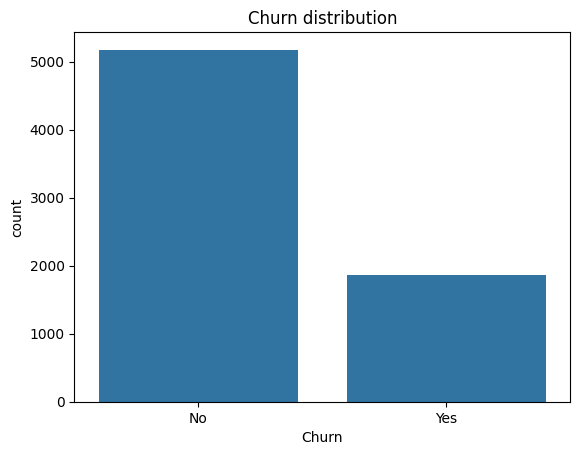

In [5]:
print(df['Churn'].value_counts(normalize=True))
sns.countplot(x='Churn', data=df)
plt.title('Churn distribution')
plt.show()

Insight: about 73.5% of customers stayed and 26.5% churned. The classes are imbalanced, so accuracy is misleading (a model that always predicts "No churn" would already score about 73%). We therefore use stratified splitting, class weights, and F1, recall and ROC-AUC as the main metrics.

2.2 Contract type , tenure and monthly charges  

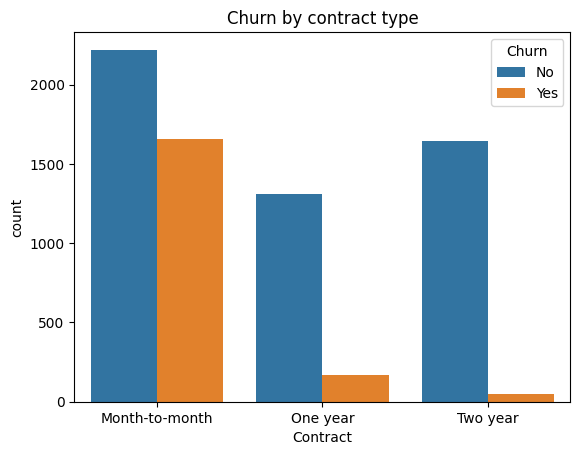

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


In [7]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by contract type');
plt.show()
print(df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean()).round(3))

Insight: month-to-month customers churn at about 42.7%, one-year at 11.3% and two-year at only 2.8%. Contract length is likely one of the strongest predictors: customers without a commitment can leave at any time.

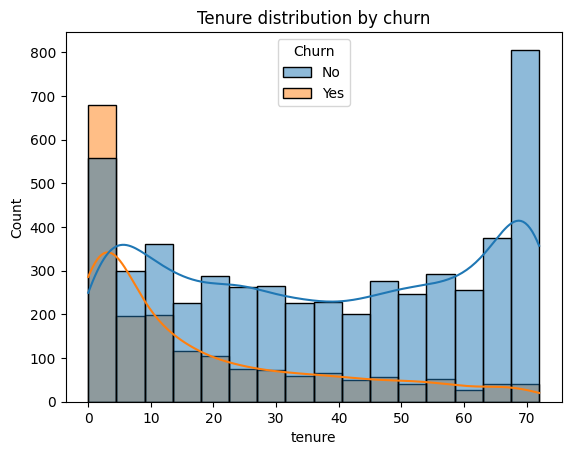

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [8]:
sns.histplot(data=df, x='tenure', hue='Churn', kde=True)
plt.title('Tenure distribution by churn');
plt.show()
print(df.groupby('Churn')['tenure'].median())

Insight: churners leave early. The median tenure of churners is about 10 months versus 38 months for loyal customers, so the first year is the highest-risk period and a good target for retention campaigns.

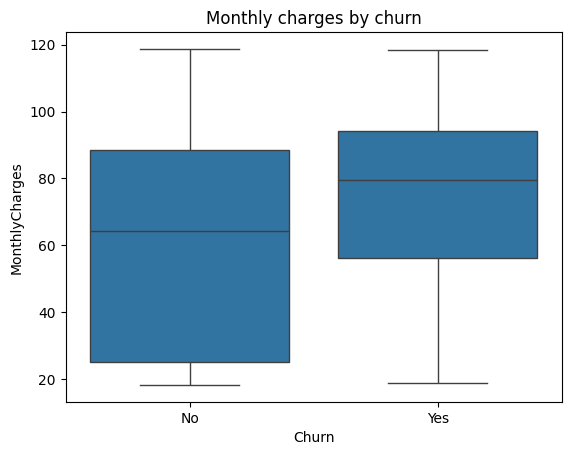

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [9]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly charges by churn');
plt.show()
print(df.groupby('Churn')['MonthlyCharges'].median())

Insight: churners pay more per month (median about 79.65 versus 64.43). Higher bills, probably fiber and add-on services, are associated with higher churn.

2.3 Services and payment

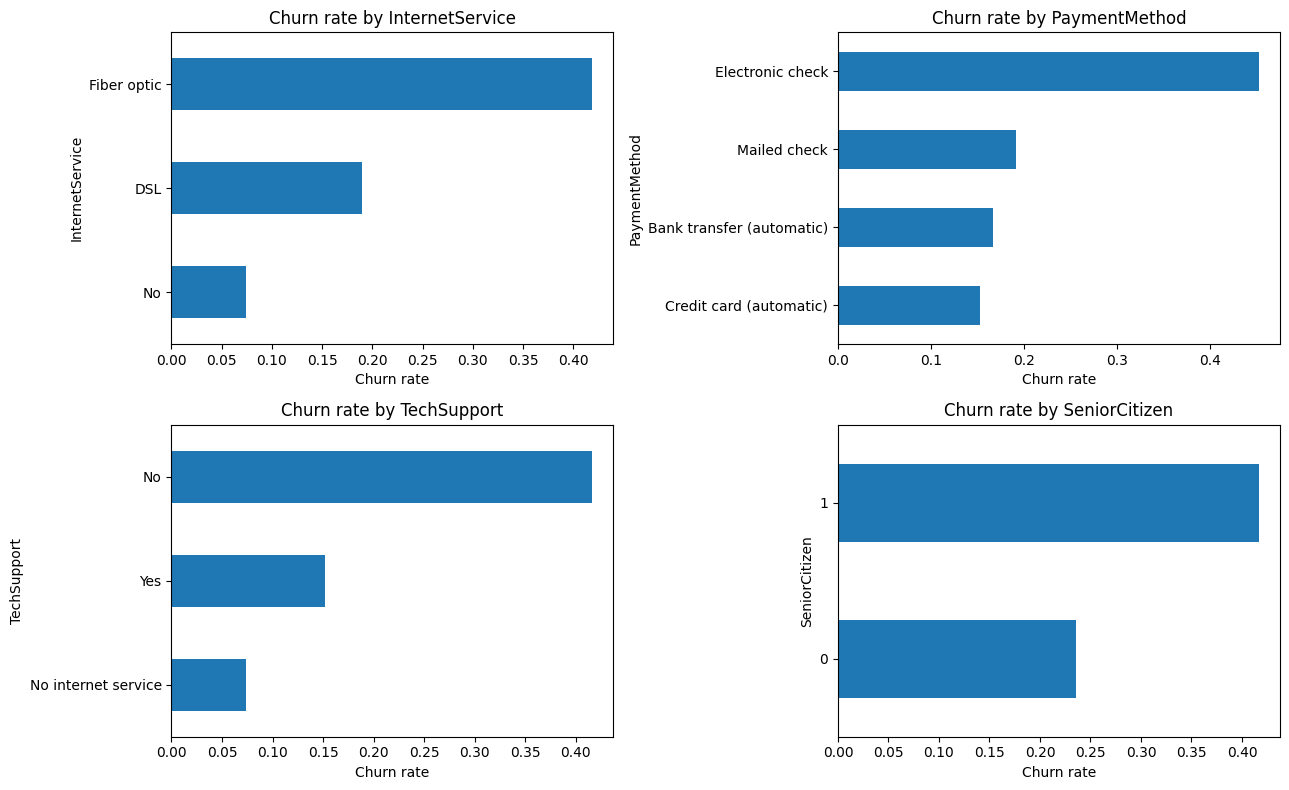

In [10]:
cols = ['InternetService', 'PaymentMethod', 'TechSupport', 'SeniorCitizen']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cols):
    rate = df.assign(c=(df['Churn'] == 'Yes')).groupby(c)['c'].mean().sort_values()
    rate.plot(kind='barh', ax=ax); ax.set_title('Churn rate by ' + c); ax.set_xlabel('Churn rate')
plt.tight_layout(); plt.show()

Insights:

Fiber optic customers churn at about 41.9%, versus 19.0% for DSL and 7.4% for customers without internet. Possible reasons (price, reliability, competition) are hypotheses that the data cannot prove.
Electronic check users churn at about 45.3%, versus roughly 15-19% for the other payment methods. Automatic payment may reflect stronger commitment.
Customers without tech support churn at about 41.6%, versus 15.2% with it.
Senior citizens churn at about 41.7% versus 23.6% for others. Gender has almost no effect (about 26.9% vs 26.2%).

2.4 Correlation of numeric features

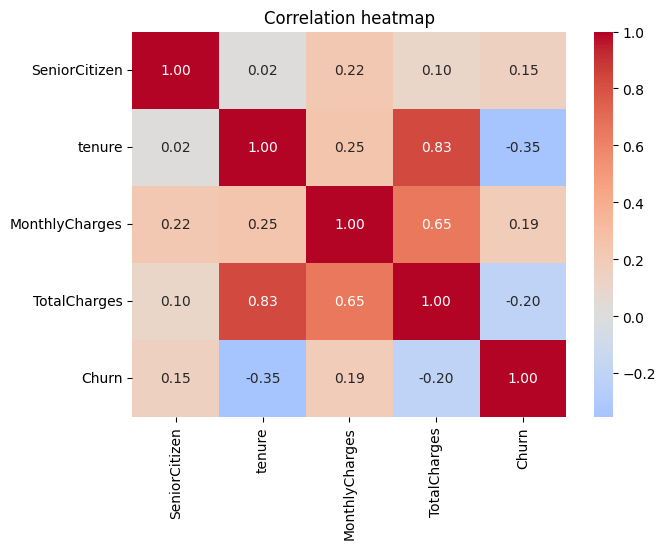

In [11]:
num_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
num_df['Churn'] = (df['Churn'] == 'Yes').astype(int)
plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap'); plt.show()

Insight: tenure and TotalCharges are strongly correlated (about 0.83) because total charges accumulate over time. This multicollinearity can make Logistic Regression coefficients less stable. tenure has the strongest negative correlation with churn (about -0.35).